# 07 · Mapas de atenção do Transformer

Extrai os pesos de atenção do Transformer da semente 42 e mede em que regiões das visões eles se concentram, no conjunto de teste. Os resultados estão no Apêndice C do TCC, Seção C.1.

Como o *embedding* convolucional tem passo 8, a atenção opera sobre 251 posições na Visão Global e 26 na Local, e não sobre os bins originais. Os mapas indicam regiões da curva, não pontos individuais.

Requer os modelos do notebook 05c e o `dataset.npz`. A GPU é opcional.

In [ ]:
import os, json
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from google.colab import drive

drive.mount('/content/drive')

DATA_DIR     = '/content/drive/MyDrive/TCC-Exoplanetas'
MODELS_DIR   = f'{DATA_DIR}/modelos'
SEMENTES_DIR = f'{MODELS_DIR}/sementes'
FIG_DIR      = f'{DATA_DIR}/figuras'
os.makedirs(FIG_DIR, exist_ok=True)

device = 'cuda' if torch.cuda.is_available() else 'cpu'
SEMENTE = 42

d = np.load(f'{DATA_DIR}/dataset.npz')
Xg, Xl, y = d['Xg_test'], d['Xl_test'], d['y_test'].astype(int)
print('teste:', Xg.shape, Xl.shape, '| positivos:', y.mean().round(3))

Mounted at /content/drive
teste: (670, 2001) (670, 201) | positivos: 0.379


## 1. Carregamento do Transformer

In [ ]:
def codificacao_posicional(comprimento, dim, device):
    pos = torch.arange(comprimento, device=device).unsqueeze(1).float()
    i   = torch.arange(dim, device=device).unsqueeze(0).float()
    ang = pos / torch.pow(torch.tensor(10000.0, device=device), (2 * (i // 2)) / dim)
    pe = torch.zeros(comprimento, dim, device=device)
    pe[:, 0::2] = torch.sin(ang[:, 0::2]); pe[:, 1::2] = torch.cos(ang[:, 1::2])
    return pe.unsqueeze(0)

class RamoTransformer(nn.Module):
    def __init__(self, d_model=64, nhead=4, camadas=2, stride=8):
        super().__init__()
        self.embed = nn.Conv1d(1, d_model, kernel_size=2 * stride + 1, stride=stride, padding=stride)
        camada = nn.TransformerEncoderLayer(d_model, nhead, dim_feedforward=128,
                                            dropout=0.1, batch_first=True)
        self.encoder = nn.TransformerEncoder(camada, camadas); self.out_dim = d_model
    def forward(self, x):
        z = self.embed(x).transpose(1, 2)
        z = z + codificacao_posicional(z.size(1), z.size(2), z.device)
        return self.encoder(z).mean(dim=1)

class DoisRamos(nn.Module):
    def __init__(self, fabrica_ramo, p_dropout=0.3):
        super().__init__()
        self.ramo_global = fabrica_ramo(); self.ramo_local = fabrica_ramo()
        d_ = self.ramo_global.out_dim
        self.cabeca = nn.Sequential(
            nn.Linear(2 * d_, 64), nn.ReLU(), nn.Dropout(p_dropout), nn.Linear(64, 1))
    def forward(self, g, l):
        return self.cabeca(torch.cat([self.ramo_global(g), self.ramo_local(l)], 1)).squeeze(-1)

# configuracao vencedora do Transformer
cfg_path, res_path = f'{MODELS_DIR}/config_final.json', f'{MODELS_DIR}/busca_resultados.json'
if os.path.exists(cfg_path):
    cfg = json.load(open(cfg_path))['transformer']
    ramo_kw = cfg['ramo']
else:
    res = json.load(open(res_path))
    cands = {k: v for k, v in res.items() if v['slug'] == 'transformer'}
    ramo_kw = cands[min(cands, key=lambda k: cands[k]['melhor_val'])]['cfg']['ramo']
print('config do ramo:', ramo_kw)

modelo = DoisRamos(lambda: RamoTransformer(**ramo_kw)).to(device)
modelo.load_state_dict(torch.load(f'{SEMENTES_DIR}/transformer_seed{SEMENTE}.pt',
                                  map_location=device))
modelo.eval()
print('modelo carregado.')

config do ramo: {'d_model': 64, 'camadas': 2}
modelo carregado.


## 2. Extração dos pesos de atenção

O `nn.TransformerEncoderLayer` do PyTorch não devolve os pesos de atenção. Por isso, o *forward* da camada é reimplementado chamando `self_attn` com `need_weights=True`. A célula seguinte confere que a reimplementação produz a mesma saída do *forward* original e interrompe a execução se houver diferença.

In [ ]:
def forward_com_atencao(ramo, x):
    """Replica o forward do ramo capturando os pesos de atencao de cada camada.
    Segue o caminho padrao do nn.TransformerEncoderLayer (norm_first=False)."""
    z = ramo.embed(x).transpose(1, 2)
    z = z + codificacao_posicional(z.size(1), z.size(2), z.device)
    pesos = []
    for camada in ramo.encoder.layers:
        attn_out, w = camada.self_attn(z, z, z, need_weights=True, average_attn_weights=True)
        pesos.append(w)                                    # (B, L, L)
        z = camada.norm1(z + camada.dropout1(attn_out))
        ff = camada.linear2(camada.dropout(camada.activation(camada.linear1(z))))
        z = camada.norm2(z + camada.dropout2(ff))
    return z.mean(dim=1), pesos


# --- VERIFICACAO ---
with torch.no_grad():
    xg = torch.from_numpy(Xg[:16]).float().unsqueeze(1).to(device)
    oficial = modelo.ramo_global(xg)
    manual, _ = forward_com_atencao(modelo.ramo_global, xg)
    dif = (oficial - manual).abs().max().item()

print(f'diferenca maxima entre forward oficial e reimplementado: {dif:.2e}')
assert dif < 1e-4, 'Reimplementacao NAO confere — nao usar estes mapas!'
print('OK — a extracao de atencao reproduz fielmente o modelo.')

diferenca maxima entre forward oficial e reimplementado: 2.38e-07
OK — a extracao de atencao reproduz fielmente o modelo.


## 3. Atenção recebida por posição

Para cada posição, calcula-se a atenção média que ela recebe das demais e, em seguida, a média entre as camadas. O resultado é um perfil de atenção ao longo da curva. O cálculo é feito em lotes, guardando só os perfis.

In [ ]:
@torch.no_grad()
def perfis_atencao(ramo, X, lote=64):
    """Devolve (N, L): atencao media recebida por posicao, media entre camadas."""
    saida = []
    for i in range(0, len(X), lote):
        x = torch.from_numpy(X[i:i+lote]).float().unsqueeze(1).to(device)
        _, pesos = forward_com_atencao(ramo, x)
        # media entre camadas; media sobre as consultas -> atencao recebida
        p = torch.stack([w.mean(dim=1) for w in pesos]).mean(dim=0)   # (B, L)
        saida.append(p.cpu().numpy())
    return np.concatenate(saida)

perf_local  = perfis_atencao(modelo.ramo_local,  Xl)
perf_global = perfis_atencao(modelo.ramo_global, Xg)
print('perfis:', perf_local.shape, perf_global.shape)

perfis: (670, 26) (670, 251)


## 4. Atenção na Visão Local

A Visão Local cobre ±4 durações de trânsito, com o trânsito no centro. Figura 13 do TCC.

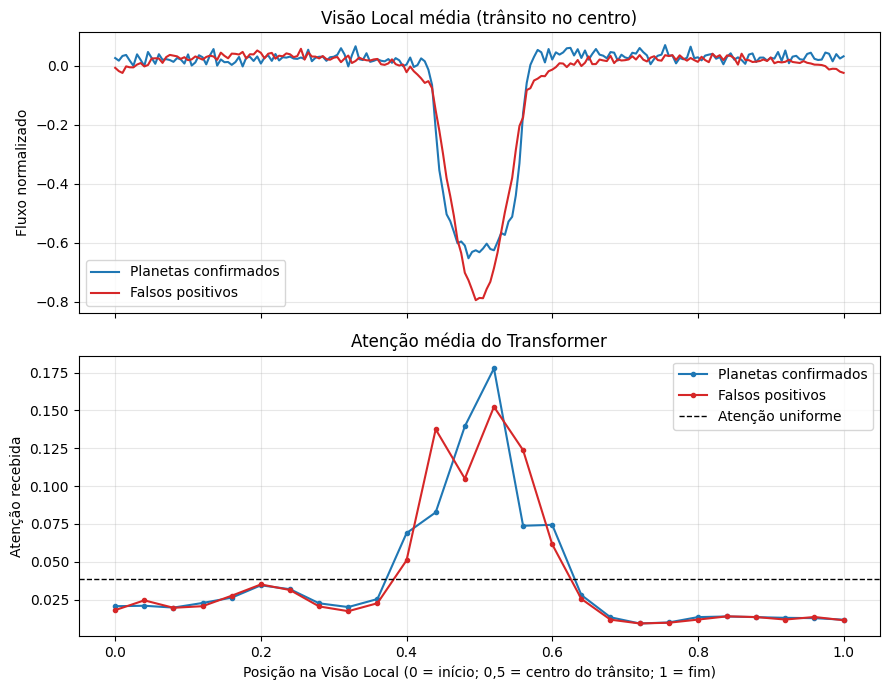

In [ ]:
def eixo_normalizado(L):
    """Posicoes do encoder mapeadas para a fracao da visao (0 a 1)."""
    return np.linspace(0, 1, L)

fig, ax = plt.subplots(2, 1, figsize=(9, 7), sharex=True)

# (a) forma media da Visao Local por classe
x_view = np.linspace(0, 1, Xl.shape[1])
ax[0].plot(x_view, Xl[y == 1].mean(0), label='Planetas confirmados', color='C0')
ax[0].plot(x_view, Xl[y == 0].mean(0), label='Falsos positivos', color='C3')
ax[0].set_ylabel('Fluxo normalizado'); ax[0].legend(); ax[0].grid(alpha=0.3)
ax[0].set_title('Visão Local média (trânsito no centro)')

# (b) atencao media por classe
x_att = eixo_normalizado(perf_local.shape[1])
ax[1].plot(x_att, perf_local[y == 1].mean(0), marker='o', ms=3, label='Planetas confirmados', color='C0')
ax[1].plot(x_att, perf_local[y == 0].mean(0), marker='o', ms=3, label='Falsos positivos', color='C3')
ax[1].axhline(1 / perf_local.shape[1], color='k', ls='--', lw=1, label='Atenção uniforme')
ax[1].set_xlabel('Posição na Visão Local (0 = início; 0,5 = centro do trânsito; 1 = fim)')
ax[1].set_ylabel('Atenção recebida'); ax[1].legend(); ax[1].grid(alpha=0.3)
ax[1].set_title('Atenção média do Transformer')

plt.tight_layout(); plt.savefig(f'{FIG_DIR}/atencao_local.png', dpi=300); plt.show()

## 5. Concentração da atenção no trânsito

A janela do trânsito corresponde a 4 das 26 posições da Visão Local (15,4%). Essa é a fração que cairia ali se a atenção fosse uniforme; a célula a compara com a fração observada em cada classe.

In [ ]:
L = perf_local.shape[1]
x_att = eixo_normalizado(L)
dentro = (x_att >= 0.5 - 1/16) & (x_att <= 0.5 + 1/16)    # janela central de 1/8
esperado = dentro.sum() / L

print(f'Janela do transito: {dentro.sum()} de {L} posicoes  (esperado sob atencao uniforme: {esperado:.1%})\n')
for classe, nome in [(1, 'Planetas confirmados'), (0, 'Falsos positivos')]:
    p = perf_local[y == classe]
    frac = p[:, dentro].sum(axis=1) / p.sum(axis=1)
    print(f'{nome:22s}: {frac.mean():.1%} da atencao no transito '
          f'(+/- {frac.std():.1%})  ->  {frac.mean()/esperado:.2f}x o esperado')

Janela do transito: 4 de 26 posicoes  (esperado sob atencao uniforme: 15.4%)

Planetas confirmados  : 47.4% da atencao no transito (+/- 5.0%)  ->  3.08x o esperado
Falsos positivos      : 51.9% da atencao no transito (+/- 8.1%)  ->  3.37x o esperado


## 6. Atenção na Visão Global

Na Visão Global, o trânsito primário fica no centro, e um eventual eclipse secundário, típico de binárias eclipsantes, aparece nas bordas. Figura 14 do TCC.

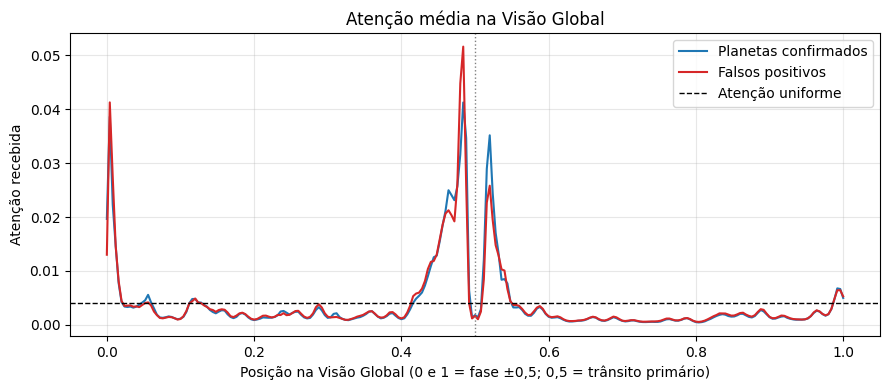

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4))
x_att_g = eixo_normalizado(perf_global.shape[1])
ax.plot(x_att_g, perf_global[y == 1].mean(0), label='Planetas confirmados', color='C0')
ax.plot(x_att_g, perf_global[y == 0].mean(0), label='Falsos positivos', color='C3')
ax.axhline(1 / perf_global.shape[1], color='k', ls='--', lw=1, label='Atenção uniforme')
ax.axvline(0.5, color='gray', ls=':', lw=1)
ax.set_xlabel('Posição na Visão Global (0 e 1 = fase ±0,5; 0,5 = trânsito primário)')
ax.set_ylabel('Atenção recebida'); ax.legend(); ax.grid(alpha=0.3)
ax.set_title('Atenção média na Visão Global')
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/atencao_global.png', dpi=300); plt.show()

### 6.1 Primário e secundário

Compara a atenção em duas janelas: a do trânsito primário, no centro, e a do eclipse secundário, nas duas bordas. Se os falsos positivos recebessem mais atenção nas bordas que os planetas, isso indicaria que o modelo usa o eclipse secundário para separá-los.

Na execução final, as duas classes receberam praticamente a mesma atenção nas bordas (13,3% e 13,5%). Os picos nas bordas são provavelmente um efeito do preenchimento (*padding*) das convoluções, discutido no Apêndice C do TCC, Seção C.4.

In [ ]:
import pandas as pd

LARGURA = 0.02        # meia-largura das janelas, em fracao da fase (2% de cada lado)

Lg = perf_global.shape[1]
xg_att = eixo_normalizado(Lg)

# duas janelas de MESMO tamanho -> comparaveis entre si
jan_primario  = np.abs(xg_att - 0.5) <= LARGURA
jan_secundario = np.minimum(xg_att, 1 - xg_att) <= LARGURA

esp_prim = jan_primario.sum() / Lg
esp_sec  = jan_secundario.sum() / Lg

print(f'Visao Global: {Lg} posicoes')
print(f'  janela do primario  : {jan_primario.sum():3d} posicoes ({esp_prim:.1%} esperado)')
print(f'  janela do secundario: {jan_secundario.sum():3d} posicoes ({esp_sec:.1%} esperado)\n')

linhas = []
for classe, nome in [(1, 'Planetas confirmados'), (0, 'Falsos positivos')]:
    p = perf_global[y == classe]
    p = p / p.sum(axis=1, keepdims=True)
    f_prim = p[:, jan_primario].sum(axis=1)
    f_sec  = p[:, jan_secundario].sum(axis=1)
    linhas.append({
        'Classe': nome,
        'Atencao no primario':   f'{f_prim.mean():.1%} ± {f_prim.std():.1%}',
        'x uniforme (prim.)':    round(f_prim.mean() / esp_prim, 2),
        'Atencao no secundario': f'{f_sec.mean():.1%} ± {f_sec.std():.1%}',
        'x uniforme (sec.)':     round(f_sec.mean() / esp_sec, 2),
    })

tab_g = pd.DataFrame(linhas)
display(tab_g)
tab_g.to_csv(f'{DATA_DIR}/atencao_global_quantificacao.csv', index=False)

# comparacao direta entre classes na janela do secundario
pp = perf_global[y == 1]; pp = pp / pp.sum(axis=1, keepdims=True)
pn = perf_global[y == 0]; pn = pn / pn.sum(axis=1, keepdims=True)
sec_pl, sec_fp = pp[:, jan_secundario].sum(axis=1), pn[:, jan_secundario].sum(axis=1)
print(f'\nJanela do secundario — planetas {sec_pl.mean():.2%} ± {sec_pl.std():.2%}  |  '
      f'falsos positivos {sec_fp.mean():.2%} ± {sec_fp.std():.2%}')
print('Faixas se sobrepoem?',
      'SIM -> tratar como equivalente' if abs(sec_pl.mean() - sec_fp.mean()) < (sec_pl.std() + sec_fp.std())
      else 'NAO -> diferenca consistente')

Visao Global: 251 posicoes
  janela do primario  :   9 posicoes (3.6% esperado)
  janela do secundario:  11 posicoes (4.4% esperado)



,Classe,Atencao no primario,x uniforme (prim.),Atencao no secundario,x uniforme (sec.)
0,Planetas confirmados,13.1% ± 5.2%,3.65,13.3% ± 3.9%,3.04
1,Falsos positivos,11.9% ± 6.7%,3.32,13.5% ± 3.6%,3.08



Janela do secundario — planetas 13.33% ± 3.86%  |  falsos positivos 13.48% ± 3.56%
Faixas se sobrepoem? SIM -> tratar como equivalente


## 7. Exemplos individuais

Curva e atenção sobrepostas em dois KOIs classificados com alta confiança.

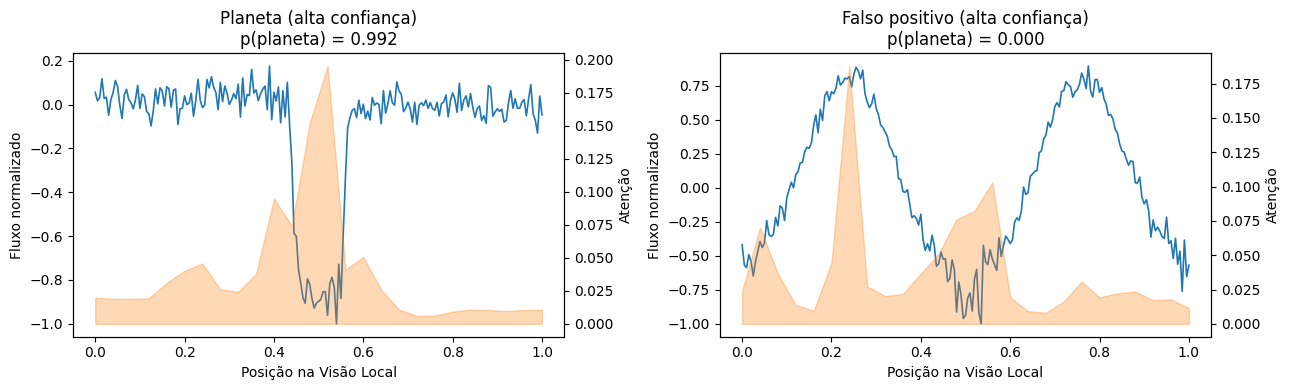

In [ ]:
with torch.no_grad():
    probs = []
    for i in range(0, len(y), 256):
        g = torch.from_numpy(Xg[i:i+256]).float().unsqueeze(1).to(device)
        l = torch.from_numpy(Xl[i:i+256]).float().unsqueeze(1).to(device)
        probs.append(torch.sigmoid(modelo(g, l)).cpu().numpy())
    probs = np.concatenate(probs)

exemplos = [(np.where(y == 1)[0][np.argmax(probs[y == 1])], 'Planeta (alta confiança)'),
            (np.where(y == 0)[0][np.argmin(probs[y == 0])], 'Falso positivo (alta confiança)')]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax_, (idx, titulo) in zip(axes, exemplos):
    ax_.plot(x_view, Xl[idx], color='C0', lw=1.2, label='Visão Local')
    ax_.set_xlabel('Posição na Visão Local'); ax_.set_ylabel('Fluxo normalizado')
    ax2 = ax_.twinx()
    ax2.fill_between(x_att, perf_local[idx], alpha=0.3, color='C1', label='Atenção')
    ax2.set_ylabel('Atenção')
    ax_.set_title(f'{titulo}\np(planeta) = {probs[idx]:.3f}')
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/atencao_exemplos.png', dpi=300); plt.show()

## Limitações

- A atenção opera sobre posições reduzidas pelo *embedding* com passo 8, com resolução de região, e não de ponto.
- Os pesos de atenção mostram onde o modelo concentra a atenção, mas não provam que essas regiões causam a decisão.
- A análise usa só o modelo da semente 42.

Figuras geradas: `atencao_local.png`, `atencao_global.png` e `atencao_exemplos.png`.